# LoRA vs LoRA+ Experimental Evaluation

## 1. Project Setup and Google Drive Integration

Clone the project repository and mount Google Drive for persistent
storage of experiment results and training checkpoints.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

import os

REPO_URL = "https://github.com/Ramprasath-Meganathan/LoRA-Plus.git"
PROJECT_DIR = "/content/LoRA_Plus_Project"

if not os.path.isdir(PROJECT_DIR):
    !git clone {REPO_URL} {PROJECT_DIR}

%cd /content/LoRA_Plus_Project

Mounted at /content/drive
Cloning into '/content/LoRA_Plus_Project'...
remote: Enumerating objects: 95, done.
remote: Counting objects: 100% (95/95), done.
remote: Compressing objects: 100% (63/63), done.
remote: Total 95 (delta 22), reused 64 (delta 13), pack-reused 0 (from 0)
Receiving objects: 100% (95/95), 218.02 KiB | 3.41 MiB/s, done.
Resolving deltas: 100% (22/22), done.
/content/LoRA_Plus_Project


## 2. Install Required Dependencies

Install the libraries required for model fine-tuning,
LoRA/LoRA+ optimization, dataset processing, and evaluation.

In [2]:
%pip install -r requirements.txt
%pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


## 3. Select Model and Dataset

Specify the pretrained model and GLUE benchmark dataset
for the current experiment.

In [3]:
MODEL_NAME = "roberta"
DATASET_NAME = "sst2"

print("Model:", MODEL_NAME)
print("Dataset:", DATASET_NAME)

Model: roberta
Dataset: sst2


## 4. Import Shared Project Modules

Import the reusable configuration, dataset preparation,
training, and evaluation functions.

In [4]:
from config import (
    COMMON_CONFIG,
    LORA_LEARNING_RATES,
    LORAPLUS_CONFIGS,
    get_output_dir
)

from utils import prepare_dataset

from train import run_experiment

from evaluate_results import (
    select_best,
    summarize_final,
    plot_convergence
)

print("All project modules imported successfully!")

All project modules imported successfully!


## 5. Dataset Loading and Preprocessing

Load the selected GLUE dataset and tokenize the input text
using the tokenizer corresponding to the selected model.

The dataset is prepared once and reused across all runs.

In [5]:
tokenizer, train_dataset, eval_dataset, data_collator = (
    prepare_dataset(
        model_name=MODEL_NAME,
        dataset_name=DATASET_NAME,
        pilot=False
    )
)

print("Training examples:", len(train_dataset))
print("Validation examples:", len(eval_dataset))

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

... (9 outputs left out)

Map:   0%|          | 0/67349 [00:00<?, ? examples/s]

Map:   0%|          | 0/872 [00:00<?, ? examples/s]

Map:   0%|          | 0/1821 [00:00<?, ? examples/s]

Model: roberta
Dataset: sst2
Training examples: 67349
Validation examples: 872
Training examples: 67349
Validation examples: 872


## 6. Sanity Test (50 Training Steps)

Verify model initialization, LoRA adapter configuration,
optimizer parameter groups, GPU compatibility, and
metric computation before running full experiments.

In [6]:
test = run_experiment(
    model_name=MODEL_NAME,
    dataset_name=DATASET_NAME,
    tokenizer=tokenizer,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    data_collator=data_collator,
    lam=4,
    seed=42,
    epochs=3,
    base_lr=1e-4,
    stage="test",
    max_steps=50
)

print(test)

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 887,042 || all params: 125,534,212 || trainable%: 0.7066
A 147456 0.0001
B 147456 0.0004
other 592130 0.0001


Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
50,0.691442,0.692687,0.509174,0.674772,0.337386


Training Loss,Validation Loss,Step,Accuracy,F1,F1 Macro
0.691442,0.692687,50,0.509174,0.674772,0.337386


{'stage': 'test', 'model': 'roberta-base', 'model_key': 'roberta', 'dataset': 'sst2', 'method': 'LoRA+', 'lam': 4, 'eta_A': 0.0001, 'eta_B': 0.0004, 'seed': 42, 'epochs': 3, 'batch_size': 32, 'max_steps': 50, 'train_examples': 67349, 'eval_examples': 872, 'final_acc': 0.5091743119266054, 'final_f1': 0.6747720364741642, 'final_f1_macro': 0.3373860182370821, 'best_acc': 0.5091743119266054, 'best_f1': 0.6747720364741642, 'best_f1_macro': 0.3373860182370821, 'final_eval_loss': 0.692687451839447, 'last_train_loss': 0.6914421081542969, 'train_runtime_s': 7.5275, 'samples_per_s': 212.555, 'total_steps': 50, 'peak_mem_gb': 1.33261568, 'trainable_params': 887042, 'torch': '2.14.1+cu130', 'transformers': '5.22.1', 'peft': '0.21.2'}


## 7. Hyperparameter Screening — Standard LoRA

Evaluate standard LoRA using three learning rates.

Both adapter matrices A and B use the same learning rate.
Each configuration is trained for three epochs using seed 42.

In [7]:
for lr in LORA_LEARNING_RATES:

    run_experiment(
        model_name=MODEL_NAME,
        dataset_name=DATASET_NAME,
        tokenizer=tokenizer,
        train_dataset=train_dataset,
        eval_dataset=eval_dataset,
        data_collator=data_collator,
        lam=1,
        seed=COMMON_CONFIG["screening_seed"],
        epochs=COMMON_CONFIG["epochs"],
        base_lr=lr,
        stage="screening"
    )

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 887,042 || all params: 125,534,212 || trainable%: 0.7066
A 147456 0.0001
B 147456 0.0001
other 592130 0.0001


Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
200,0.336899,0.265890,0.902523,0.905240,0.902443
400,0.299756,0.234826,0.908257,0.911111,0.908162
600,0.259730,0.219863,0.917431,0.919101,0.917396
800,0.251512,0.216115,0.919725,0.921525,0.919683
1000,0.251491,0.219909,0.913991,0.917310,0.913852
1200,0.256438,0.213848,0.917431,0.920705,0.917290
1400,0.246528,0.212143,0.924312,0.926667,0.924234
1600,0.263081,0.201632,0.927752,0.928490,0.927745
1800,0.243905,0.205860,0.928899,0.930493,0.928862
2000,0.235767,0.206509,0.924312,0.926991,0.924210


Training Loss,Validation Loss,Step,Accuracy,F1,F1 Macro
0.220175,0.199357,6315,0.934633,0.936170,0.934595


Saved result: /content/drive/MyDrive/LoRA_Plus_Project/modular_v2/roberta/sst2/runs/roberta_sst2_lam1_lr0.0001_seed42_ep3_bs32_steps-1_screening.json


... (9 outputs left out)

trainable params: 887,042 || all params: 125,534,212 || trainable%: 0.7066
A 147456 0.0004
B 147456 0.0004
other 592130 0.0001


Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
200,0.292475,0.256980,0.905963,0.910870,0.905678
400,0.278835,0.207226,0.917431,0.920177,0.917333
600,0.255002,0.205295,0.930046,0.931073,0.930030
800,0.248328,0.204692,0.926606,0.928731,0.926540
1000,0.237763,0.248166,0.912844,0.917570,0.912557
1200,0.239040,0.194648,0.931193,0.933036,0.931140
1400,0.226381,0.198759,0.932339,0.933484,0.932319
1600,0.247181,0.197096,0.927752,0.927503,0.927751
1800,0.230698,0.206379,0.928899,0.931111,0.928826
2000,0.215366,0.213666,0.925459,0.928650,0.925309


Training Loss,Validation Loss,Step,Accuracy,F1,F1 Macro
0.181304,0.201716,6315,0.938073,0.939189,0.938053


Saved result: /content/drive/MyDrive/LoRA_Plus_Project/modular_v2/roberta/sst2/runs/roberta_sst2_lam1_lr0.0004_seed42_ep3_bs32_steps-1_screening.json


## 8. Hyperparameter Screening — LoRA+

Evaluate LoRA+ using six combinations of base learning
rates and learning-rate ratios.

Matrix B uses a larger learning rate than matrix A:

eta_B = lambda * eta_A

Each configuration is trained for three epochs using seed 42.

In [8]:
for lr, ratio in LORAPLUS_CONFIGS:

    run_experiment(
        model_name=MODEL_NAME,
        dataset_name=DATASET_NAME,
        tokenizer=tokenizer,
        train_dataset=train_dataset,
        eval_dataset=eval_dataset,
        data_collator=data_collator,
        lam=ratio,
        seed=COMMON_CONFIG["screening_seed"],
        epochs=COMMON_CONFIG["epochs"],
        base_lr=lr,
        stage="screening"
    )

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 887,042 || all params: 125,534,212 || trainable%: 0.7066
A 147456 0.0001
B 147456 0.0004
other 592130 0.0001


Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
200,0.298472,0.250041,0.909404,0.912707,0.909274
400,0.281823,0.226263,0.909404,0.913472,0.909203
600,0.261261,0.203404,0.920872,0.922385,0.920841
800,0.249682,0.213605,0.922018,0.924276,0.921949
1000,0.243279,0.240716,0.913991,0.918743,0.913696
1200,0.250681,0.207820,0.922018,0.924945,0.921900
1400,0.239097,0.208619,0.926606,0.928090,0.926574
1600,0.256337,0.198292,0.931193,0.931973,0.931184
1800,0.239711,0.208649,0.931193,0.933481,0.931111
2000,0.225703,0.206620,0.928899,0.931567,0.928791


Training Loss,Validation Loss,Step,Accuracy,F1,F1 Macro
0.204228,0.197538,6315,0.934633,0.936027,0.934602


Saved result: /content/drive/MyDrive/LoRA_Plus_Project/modular_v2/roberta/sst2/runs/roberta_sst2_lam4_lr0.0001_seed42_ep3_bs32_steps-1_screening.json


... (27 outputs left out)

trainable params: 887,042 || all params: 125,534,212 || trainable%: 0.7066
A 147456 0.0002
B 147456 0.0032
other 592130 0.0001


Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
200,0.324981,0.242683,0.916284,0.920219,0.916080
400,0.300637,0.203845,0.919725,0.922049,0.919653
600,0.255313,0.202742,0.919725,0.920455,0.919718
800,0.239646,0.241548,0.925459,0.928493,0.925324
1000,0.242722,0.282003,0.913991,0.919786,0.913540
1200,0.233310,0.215125,0.925459,0.928650,0.925309
1400,0.228910,0.207877,0.927752,0.928814,0.927736
1600,0.236627,0.211390,0.939220,0.940649,0.939185
1800,0.231874,0.212792,0.924312,0.926503,0.924245
2000,0.214132,0.235051,0.925459,0.929425,0.925223


Training Loss,Validation Loss,Step,Accuracy,F1,F1 Macro
0.158464,0.203691,6315,0.936927,0.938410,0.936890


Saved result: /content/drive/MyDrive/LoRA_Plus_Project/modular_v2/roberta/sst2/runs/roberta_sst2_lam16_lr0.0002_seed42_ep3_bs32_steps-1_screening.json


## 9. Best Hyperparameter Selection

Select the best standard LoRA and LoRA+ configurations
based on validation performance.

SST-2 uses accuracy as the primary metric.
QQP uses binary F1 as the primary metric.

In [9]:
best_lora, best_loraplus = select_best(
    MODEL_NAME,
    DATASET_NAME
)

BEST_LORA_LR = float(best_lora["eta_A"])

BEST_LORAPLUS_LR = float(best_loraplus["eta_A"])
BEST_LAM = int(best_loraplus["lam"])

print("Best LoRA learning rate:", BEST_LORA_LR)
print("Best LoRA+ learning rate:", BEST_LORAPLUS_LR)
print("Best LoRA+ ratio:", BEST_LAM)


Best standard LoRA:
eta_A          0.0004
eta_B          0.0004
final_acc    0.938073
Name: 2, dtype: object

Best LoRA+:
eta_A         0.0002
eta_B         0.0016
lam                8
final_acc    0.93922
Name: 7, dtype: object
Best LoRA learning rate: 0.0004
Best LoRA+ learning rate: 0.0002
Best LoRA+ ratio: 8


## 10. Final Multi-Seed Experiments

Evaluate the selected LoRA and LoRA+ configurations
across three random seeds: 42, 43, and 44.

Each run trains a fresh model for three epochs.

In [12]:
for seed in COMMON_CONFIG["seeds"]:

    # Standard LoRA
    run_experiment(
        model_name=MODEL_NAME,
        dataset_name=DATASET_NAME,
        tokenizer=tokenizer,
        train_dataset=train_dataset,
        eval_dataset=eval_dataset,
        data_collator=data_collator,
        lam=1,
        seed=seed,
        epochs=COMMON_CONFIG["epochs"],
        base_lr=BEST_LORA_LR,
        stage="final"
    )

    # LoRA+
    run_experiment(
        model_name=MODEL_NAME,
        dataset_name=DATASET_NAME,
        tokenizer=tokenizer,
        train_dataset=train_dataset,
        eval_dataset=eval_dataset,
        data_collator=data_collator,
        lam=BEST_LAM,
        seed=seed,
        epochs=COMMON_CONFIG["epochs"],
        base_lr=BEST_LORAPLUS_LR,
        stage="final"
    )

Already completed: roberta_sst2_lam1_lr0.0004_seed42_ep3_bs32_steps-1_final
Already completed: roberta_sst2_lam8_lr0.0002_seed42_ep3_bs32_steps-1_final
Already completed: roberta_sst2_lam1_lr0.0004_seed43_ep3_bs32_steps-1_final
Already completed: roberta_sst2_lam8_lr0.0002_seed43_ep3_bs32_steps-1_final


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 887,042 || all params: 125,534,212 || trainable%: 0.7066
A 147456 0.0004
B 147456 0.0004
other 592130 0.0001


Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
200,0.330101,0.214382,0.912844,0.914798,0.912798
400,0.267814,0.217976,0.917431,0.920879,0.917274
600,0.257143,0.208352,0.926606,0.928731,0.926540
800,0.261113,0.200163,0.927752,0.929134,0.927725
1000,0.229972,0.197155,0.932339,0.933031,0.932332
1200,0.241746,0.198117,0.932339,0.933782,0.932307
1400,0.262089,0.194327,0.932339,0.933182,0.932329
1600,0.228796,0.207316,0.934633,0.935301,0.934626
1800,0.221355,0.198173,0.935780,0.936073,0.935778
2000,0.221417,0.190638,0.936927,0.938272,0.936897


Training Loss,Validation Loss,Step,Accuracy,F1,F1 Macro
0.167432,0.210003,6315,0.941514,0.942373,0.941501


... (4 outputs left out)

Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
200,0.324247,0.215137,0.920872,0.922034,0.920854
400,0.275236,0.224350,0.917431,0.920000,0.917346
600,0.261860,0.238683,0.916284,0.920566,0.916040
800,0.267471,0.209654,0.926606,0.928090,0.926574
1000,0.233900,0.206741,0.932339,0.934078,0.932292
1200,0.234724,0.212089,0.925459,0.926884,0.925430
1400,0.259190,0.200716,0.932339,0.933782,0.932307
1600,0.226146,0.211941,0.934633,0.935738,0.934614
1800,0.220877,0.228993,0.936927,0.938547,0.936883
2000,0.222714,0.209493,0.936927,0.938957,0.936857


Step,Training Loss,Validation Loss,Accuracy,F1,F1 Macro
200,0.324247,0.215137,0.920872,0.922034,0.920854
400,0.275236,0.224350,0.917431,0.920000,0.917346
600,0.261860,0.238683,0.916284,0.920566,0.916040
800,0.267471,0.209654,0.926606,0.928090,0.926574
1000,0.233900,0.206741,0.932339,0.934078,0.932292
1200,0.234724,0.212089,0.925459,0.926884,0.925430
1400,0.259190,0.200716,0.932339,0.933782,0.932307
1600,0.226146,0.211941,0.934633,0.935738,0.934614
1800,0.220877,0.228993,0.936927,0.938547,0.936883
2000,0.222714,0.209493,0.936927,0.938957,0.936857


Training Loss,Validation Loss,Step,Accuracy,F1,F1 Macro
0.162838,0.226478,6315,0.934633,0.935883,0.934608


Saved result: /content/drive/MyDrive/LoRA_Plus_Project/modular_v2/roberta/sst2/runs/roberta_sst2_lam8_lr0.0002_seed44_ep3_bs32_steps-1_final.json


## 11. Final Performance Comparison

Aggregate results across three random seeds.

Report mean and standard deviation for accuracy,
F1, validation loss, training runtime, GPU memory,
and trainable parameter count.

In [13]:
summary = summarize_final(
    MODEL_NAME,
    DATASET_NAME
)

display(summary)


Best standard LoRA:
eta_A          0.0004
eta_B          0.0004
final_acc    0.938073
Name: 2, dtype: object

Best LoRA+:
eta_A         0.0002
eta_B         0.0016
lam                8
final_acc    0.93922
Name: 7, dtype: object

Final results:
                  final_acc            final_f1           final_f1_macro           final_eval_loss           train_runtime_s           peak_mem_gb           trainable_params     
                       mean       std      mean       std           mean       std            mean       std            mean       std        mean       std             mean  std
method lam eta_A                                                                                                                                                                  
LoRA   1   0.0004  0.939220  0.001986  0.940250  0.001838       0.939202  0.001991        0.206198  0.004185        463.2518  0.473328    1.394070  0.002214         887042.0  0.0
LoRA+  8   0.0002  0.936162  0.002648 

final_acc            final_f1           final_f1_macro  \
                       mean       std      mean       std           mean   
method lam eta_A                                                           
LoRA   1   0.0004  0.939220  0.001986  0.940250  0.001838       0.939202   
LoRA+  8   0.0002  0.936162  0.002648  0.937293  0.002442       0.936141   

                            final_eval_loss           train_runtime_s  \
                        std            mean       std            mean   
method lam eta_A                                                        
LoRA   1   0.0004  0.001991        0.206198  0.004185        463.2518   
LoRA+  8   0.0002  0.002655        0.213731  0.011750        463.5156   

                            peak_mem_gb           trainable_params       
                        std        mean       std             mean  std  
method lam eta_A                                                         
LoRA   1   0.0004  0.473328    1.394070  0.002214         887042.0  0.0  
LoRA+  8   0.0002  3.365498    1.393261  0.000928         887042.0  0.0

## 12. Convergence Analysis

Compare standard LoRA and LoRA+ convergence using
validation performance against optimizer steps.

Display mean performance across three seeds,
with standard-deviation bands.


Best standard LoRA:
eta_A          0.0004
eta_B          0.0004
final_acc    0.938073
Name: 2, dtype: object

Best LoRA+:
eta_A         0.0002
eta_B         0.0016
lam                8
final_acc    0.93922
Name: 7, dtype: object


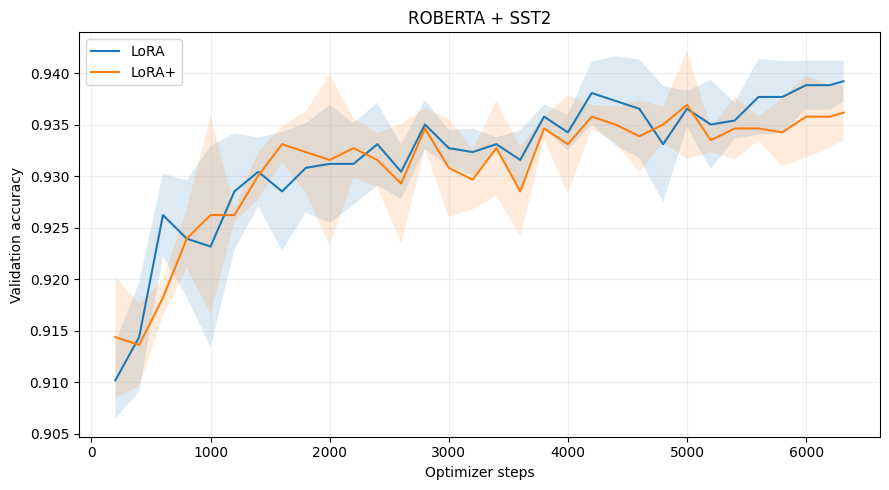

Saved: /content/drive/MyDrive/LoRA_Plus_Project/modular_v2/roberta/sst2/convergence.png


In [14]:
plot_convergence(
    MODEL_NAME,
    DATASET_NAME
)